In [ ]:
using DataFrames, CSV

"""
    load_baci(folder, years; product=270900, version="V202601", hs="HS17")

Loads the BACI files for the requested `years`, keeps only `product`
(default 270900, crude oil), and returns one DataFrame with named columns.
"""

function load_baci(folder::AbstractString, years::AbstractVector{<:Integer};
                   product::Integer = 270900,
                   version::AbstractString = "V202601",
                   hs::AbstractString = "HS17")

    # Country names
    cc = CSV.read(joinpath(folder, "country_codes_$(version).csv"), DataFrame;
                  select = ["country_code", "country_name"])
    cc.country_code = Int16.(cc.country_code)

    frames = DataFrame[]
    for y in years
        path = joinpath(folder, "BACI_$(hs)_Y$(y)_$(version).csv")
        isfile(path) || error("File not found: $path")

        df = CSV.read(path, DataFrame;
                      select = ["t", "i", "j", "k", "v", "q"],
                      types = Dict("t" => Int16, "i" => Int16, "j" => Int16,
                                   "k" => Int32, "v" => Float64, "q" => Float64),
                      missingstring = ["NA", ""])

        push!(frames, df[df.k .== product, :])      # keep only crude oil
    end

    out = reduce(vcat, frames)

    rename!(out, "t" => "year",
                 "i" => "exporter_code",
                 "j" => "importer_code",
                 "k" => "product",
                 "v" => "value_kUSD",
                 "q" => "quantity_tons")

    out = leftjoin(out, rename(cc, "country_code" => "exporter_code",
                                   "country_name" => "exporter"), on = "exporter_code")
    out = leftjoin(out, rename(cc, "country_code" => "importer_code",
                                   "country_name" => "importer"), on = "importer_code")

    select!(out, "year", "exporter_code", "exporter", "importer_code", "importer",
                 "product", "value_kUSD", "quantity_tons")
    sort!(out, ["year", "value_kUSD"], rev = [false, true])
    return out
end


"""
    build_trade_network(df; directed=false, weight_by_volume=false, weight_by_value=false)

Builds a trade network from the DataFrame returned by `load_baci`.

- `directed=true`  : edge exporter -> importer.
  `directed=false` : undirected edge between the two trading countries
                     (flows in both directions are combined).
- `weight_by_volume=true` : weights = quantity_tons
- `weight_by_value=true`  : weights = value_kUSD
- both false              : unweighted network.
- both true               : raises an ArgumentError.

If `df` holds several years, flows are summed over the years (filter `df` first
for a single-year network).

Returns a NamedTuple `(graph, codes, labels)`, where `labels[n]` is the country
name of vertex `n` and `codes[n]` its BACI country code.
"""
function build_trade_network(df::DataFrame;
                             directed::Bool = false,
                             weight_by_volume::Bool = false,
                             weight_by_value::Bool = false)

    weight_by_volume && weight_by_value &&
        throw(ArgumentError("weight_by_volume and weight_by_value cannot both be true."))

    wcol = weight_by_volume ? :quantity_tons :
           weight_by_value  ? :value_kUSD    : nothing

    # ---- Vertices: every country that appears as exporter or importer ----
    codes = sort(unique(vcat(df.exporter_code, df.importer_code)))
    idx   = Dict(c => n for (n, c) in enumerate(codes))
    n     = length(codes)

    name_of = Dict{Int16,String}()
    for r in eachrow(df)
        name_of[r.exporter_code] = string(coalesce(r.exporter, "Unknown $(r.exporter_code)"))
        name_of[r.importer_code] = string(coalesce(r.importer, "Unknown $(r.importer_code)"))
    end
    labels = [name_of[c] for c in codes]

    # ---- Aggregate flows per edge ----
    edges = Dict{Tuple{Int,Int},Float64}()
    for r in eachrow(df)
        s, d = idx[r.exporter_code], idx[r.importer_code]
        s == d && continue                                  # ignore self-loops
        key = directed ? (s, d) : minmax(s, d)              # undirected: merge A->B and B->A
        w = wcol === nothing ? 1.0 : r[wcol]
        ismissing(w) && continue                            # skip missing quantities
        edges[key] = get(edges, key, 0.0) + w
    end

    # ---- Build the graph ----
    if wcol === nothing
        g = directed ? SimpleDiGraph(n) : SimpleGraph(n)
        for (s, d) in keys(edges)
            add_edge!(g, s, d)
        end
    else
        g = directed ? SimpleWeightedDiGraph(n) : SimpleWeightedGraph(n)
        for ((s, d), w) in edges
            w > 0 && add_edge!(g, s, d, w)                  # weight 0 would not create an edge
        end
    end

    return (graph = g, codes = codes, labels = labels)
end


In [2]:
using DataFrames, CSV, Graphs, SimpleWeightedGraphs, SparseArrays, DataFrames, Random

"""
    build_trade_network(df; directed=false, weight_by_volume=false, weight_by_value=false)

Builds a trade network from the DataFrame returned by `load_baci`.

- `directed=true`  : edge exporter -> importer.
  `directed=false` : undirected edge between the two trading countries
                     (flows in both directions are combined).
- `weight_by_volume=true` : weights = quantity_tons
- `weight_by_value=true`  : weights = value_kUSD
- both false              : unweighted network.
- both true               : raises an ArgumentError.

If `df` holds several years, flows are summed over the years (filter `df` first
for a single-year network).

Returns a NamedTuple `(graph, codes, labels)`, where `labels[n]` is the country
name of vertex `n` and `codes[n]` its BACI country code.
"""
function build_trade_network(df::DataFrame;
                             directed::Bool = false,
                             weight_by_volume::Bool = false,
                             weight_by_value::Bool = false)

    weight_by_volume && weight_by_value &&
        throw(ArgumentError("weight_by_volume and weight_by_value cannot both be true."))

    wcol = weight_by_volume ? :quantity_tons :
           weight_by_value  ? :value_kUSD    : nothing

    # ---- Vertices: every country that appears as exporter or importer ----
    codes = sort(unique(vcat(df.exporter_code, df.importer_code)))
    idx   = Dict(c => n for (n, c) in enumerate(codes))
    n     = length(codes)

    name_of = Dict{Int16,String}()
    for r in eachrow(df)
        name_of[r.exporter_code] = string(coalesce(r.exporter, "Unknown $(r.exporter_code)"))
        name_of[r.importer_code] = string(coalesce(r.importer, "Unknown $(r.importer_code)"))
    end
    labels = [name_of[c] for c in codes]

    # ---- Aggregate flows per edge ----
    edges = Dict{Tuple{Int,Int},Float64}()
    for r in eachrow(df)
        s, d = idx[r.exporter_code], idx[r.importer_code]
        s == d && continue                                  # ignore self-loops
        key = directed ? (s, d) : minmax(s, d)              # undirected: merge A->B and B->A
        w = wcol === nothing ? 1.0 : r[wcol]
        ismissing(w) && continue                            # skip missing quantities
        edges[key] = get(edges, key, 0.0) + w
    end

    # ---- Build the graph ----
    if wcol === nothing
        g = directed ? SimpleDiGraph(n) : SimpleGraph(n)
        for (s, d) in keys(edges)
            add_edge!(g, s, d)
        end
    else
        g = directed ? SimpleWeightedDiGraph(n) : SimpleWeightedGraph(n)
        for ((s, d), w) in edges
            w > 0 && add_edge!(g, s, d, w)                  # weight 0 would not create an edge
        end
    end

    return (graph = g, codes = codes, labels = labels)
end

build_trade_network

In [6]:
crude = CSV.read("clean_data/crude_2021.csv",DataFrame)

# ---------------- Examples ----------------

#net_u  = build_trade_network(crude)                                   # undirected, unweighted
#net_d  = build_trade_network(crude; directed = true)                  # directed, unweighted
net_dv = build_trade_network(crude; directed = true, weight_by_value = true)
#net_uq = build_trade_network(crude; weight_by_volume = true)

# build_trade_network(crude; weight_by_value = true, weight_by_volume = true)  # -> ArgumentError

g = net_dv.graph
println("Nodes: ", nv(g), " | Edges: ", ne(g))

Nodes: 186 | Edges: 1515


In [10]:
using Printf

"""
    country_report(net, country; top=5, n_suggest=5, unit="")

Prints a profile of `country` in the network `net` (output of `build_trade_network`):
  - weighted graph   -> top trade partners ranked by weight (exports to / imports from if directed)
  - unweighted graph -> list of immediate trade partners
  - number of triangles the country belongs to
  - triadic closure: non-partners that share the most partners with the country
Triangles and triadic closure use the undirected projection (direction ignored).
"""

function country_report(net, country::AbstractString;
                        top::Int = 5, n_suggest::Int = 5, unit::AbstractString = "")

    g, labels = net.graph, net.labels
    directed = is_directed(g)
    weighted = g isa AbstractSimpleWeightedGraph

    # ---- find the node (exact match first, then substring) ----
    q = lowercase(country)
    hits = findall(l -> lowercase(l) == q, labels)
    isempty(hits) && (hits = findall(l -> occursin(q, lowercase(l)), labels))
    isempty(hits) && error("No country matching \"$country\"")
    length(hits) > 1 && error("Ambiguous name, matches: ", join(labels[hits], "; "))
    v = only(hits)

    W = weighted ? weights(g) : nothing

    # ---- helper: print a list of partners ----
    function show_partners(title, nodes, wfun)
        println("\n", title, " (", length(nodes), " countries)")
        if isempty(nodes)
            println("  none")
        elseif weighted
            order = sort(nodes, by = wfun, rev = true)
            tot = sum(wfun, nodes)
            for u in first(order, top)
                @printf("  %-32s %14.1f %s (%.1f%%)\n", labels[u], wfun(u), unit, 100 * wfun(u) / tot)
            end
            length(order) > top && println("  ... and ", length(order) - top, " more")
        else
            println("  ", join(sort(labels[nodes]), ", "))
        end
    end

    println("="^60)
    println("Country: ", labels[v], "  (node ", v, ")")
    println("Network: ", directed ? "directed" : "undirected", ", ",
            weighted ? "weighted" : "unweighted")
    println("="^60)

    # ---- partners ----
    if directed
        outs, ins = outneighbors(g, v), inneighbors(g, v)
        show_partners("Exports to", outs, u -> W[v, u])
        show_partners("Imports from", ins, u -> W[u, v])
    else
        nb = neighbors(g, v)
        show_partners("Trade partners", nb, u -> W[v, u])
    end

    # ---- undirected neighbourhood for triangles / closure ----
    nbr(u) = directed ? union(outneighbors(g, u), inneighbors(g, u)) : neighbors(g, u)
    Nv = Set(nbr(v)); delete!(Nv, v)
    nvec = collect(Nv)
    Nsets = Dict(u => Set(nbr(u)) for u in nvec)

    # ---- triangles ----
    tri = 0
    for a in 1:length(nvec), b in (a + 1):length(nvec)
        nvec[b] in Nsets[nvec[a]] && (tri += 1)
    end
    println("\nTriangles ", labels[v], " is part of: ", tri)

    # ---- triadic closure: non-partners with most shared partners ----
    common = Dict{Int,Vector{Int}}()
    for u in nvec, w in Nsets[u]
        (w == v || w in Nv) && continue
        push!(get!(common, w, Int[]), u)
    end

    cands = [(w, length(c), length(c) / (length(Nv) + length(nbr(w)) - length(c)))
             for (w, c) in common]
    sort!(cands, by = x -> (x[2], x[3]), rev = true)

    println("\nTriadic closure: countries likely to form a trade link with ", labels[v])
    println("(not partners now, ranked by number of shared partners)")
    if isempty(cands)
        println("  none")
    else
        for (w, k, _) in first(cands, n_suggest)
            via = sort(labels[common[w]])
            shown = join(first(via, 3), ", ") * (length(via) > 3 ? ", ..." : "")
            @printf("  %-32s %3d shared partners  (e.g. %s)\n", labels[w], k, shown)
        end
    end
    return nothing
end


country_report (generic function with 1 method)

In [14]:
# ---------------- Examples ----------------
country_report(net_dv, "Saudi Arabia"; unit = "kUSD")

Country: Saudi Arabia  (node 144)
Network: directed, weighted

Exports to (31 countries)
  China                                43938620.7 kUSD (28.2%)
  Japan                                25224810.9 kUSD (16.2%)
  Rep. of Korea                        21320549.6 kUSD (13.7%)
  India                                17905752.9 kUSD (11.5%)
  USA                                   8992009.9 kUSD (5.8%)
  ... and 26 more

Imports from (3 countries)
  Rep. of Moldova                            74.2 kUSD (91.8%)
  United Arab Emirates                        3.8 kUSD (4.7%)
  France                                      2.8 kUSD (3.5%)

Triangles Saudi Arabia is part of: 238

Triadic closure: countries likely to form a trade link with Saudi Arabia
(not partners now, ranked by number of shared partners)
  Nigeria                           26 shared partners  (e.g. Belgium, Brazil, Brunei Darussalam, ...)
  Russian Federation                23 shared partners  (e.g. Belgium, Brazil, Brunei Darus

In [16]:
country_report(net_dv, "Chile")

Country: Chile  (node 32)
Network: directed, weighted

Exports to (3 countries)
  Singapore                                   0.0  (46.4%)
  Belgium                                     0.0  (44.3%)
  Rep. of Korea                               0.0  (9.3%)

Imports from (9 countries)
  Brazil                                2039162.4  (51.0%)
  Ecuador                                719727.1  (18.0%)
  Angola                                 487458.2  (12.2%)
  USA                                    421155.0  (10.5%)
  Canada                                 196646.9  (4.9%)
  ... and 4 more

Triangles Chile is part of: 46

Triadic closure: countries likely to form a trade link with Chile
(not partners now, ranked by number of shared partners)
  United Arab Emirates              11 shared partners  (e.g. Angola, Argentina, Belgium, ...)
  Norway                            10 shared partners  (e.g. Angola, Belgium, Brazil, ...)
  India                             10 shared partners  (e.g. A

In [32]:
using Graphs, SimpleWeightedGraphs, SparseArrays, DataFrames, Random

# Unweighted copy of the graph (centralities like betweenness/closeness would otherwise
# treat trade weights as distances, which is wrong for flows).
function _topology(g)
    g isa AbstractSimpleWeightedGraph || return g
    t = is_directed(g) ? SimpleDiGraph(nv(g)) : SimpleGraph(nv(g))
    for e in edges(g)
        add_edge!(t, src(e), dst(e))
    end
    return t
end

function _centrality(topo, W, c::Symbol)
    n = nv(topo)
    c === :degree      && return degree_centrality(topo; normalize = false)
    c === :indegree    && return indegree_centrality(topo; normalize = false)
    c === :outdegree   && return outdegree_centrality(topo; normalize = false)
    c === :betweenness && return betweenness_centrality(topo)
    c === :closeness   && return closeness_centrality(topo)
    c === :eigenvector && return eigenvector_centrality(topo)
    c === :pagerank    && return pagerank(topo)
    c === :random      && return rand(n)                      # baseline
    if c in (:strength, :instrength, :outstrength)
        W === nothing && error("$c requires a weighted network.")
        out = vec(sum(W, dims = 2)); inn = vec(sum(W, dims = 1))
        return c === :outstrength ? out : c === :instrength ? inn :
               (is_directed(topo) ? out .+ inn : out)
    end
    error("Unknown centrality :$c. Options: :degree, :indegree, :outdegree, :strength, " *
          ":instrength, :outstrength, :betweenness, :closeness, :eigenvector, :pagerank, :random")
end

function _metrics(sub, N0)
    und   = SimpleGraph(sub)                       # undirected projection
    comps = connected_components(und)
    sizes = length.(comps)
    lcc   = comps[argmax(sizes)]
    n     = nv(sub)

    avg_path = NaN
    if length(lcc) > 1
        sg, _ = induced_subgraph(und, lcc)
        m = nv(sg)
        avg_path = sum(sum(gdistances(sg, u)) for u in vertices(sg)) / (m * (m - 1))
    end

    return (nodes_left   = n,
            edges        = ne(sub),
            isolated     = count(==(0), degree(und)),
            components   = count(>(1), sizes),     # components with at least 2 countries
            lcc_size     = length(lcc),
            lcc_frac     = length(lcc) / N0,       # relative to the ORIGINAL number of countries
            density      = n > 1 ? Graphs.density(sub) : NaN,
            transitivity = n > 2 ? global_clustering_coefficient(und) : NaN,
            avg_path_lcc = avg_path)
end

"""
    attack_test(net, centrality; steps=10, recompute=true)

Removes, one at a time, the country with the highest `centrality` and records the
network structure after each removal.

- `centrality`: :degree, :indegree, :outdegree, :strength, :instrength, :outstrength,
                :betweenness, :closeness, :eigenvector, :pagerank, or :random (baseline).
- `steps`     : number of countries to remove.
- `recompute` : true  -> recompute centrality after every removal (adaptive attack);
                false -> rank once on the original network and remove in that order.

Returns `(history, removed)`: a DataFrame (row 0 = intact network) and the removed countries.
"""
function attack_test(net, centrality::Symbol; steps::Int = 10, recompute::Bool = true)
    g, labels = net.graph, net.labels
    topo = _topology(g)
    W    = g isa AbstractSimpleWeightedGraph ? weights(g) : nothing
    N0   = nv(topo)
    steps = min(steps, N0 - 1)

    alive   = collect(1:N0)
    removed = Int[]
    rows    = NamedTuple[]

    push!(rows, merge((step = 0, removed = "-", centrality = NaN), _metrics(topo, N0)))

    static_order = recompute ? Int[] :
        sortperm(_centrality(topo, W, centrality), rev = true)

    for s in 1:steps
        if recompute
            sub, _ = induced_subgraph(topo, alive)
            Wsub   = W === nothing ? nothing : W[alive, alive]
            cent   = _centrality(sub, Wsub, centrality)
            k      = argmax(cent)
            node, val = alive[k], cent[k]
        else
            node = static_order[s]
            val  = NaN
        end
        push!(removed, node)
        filter!(!=(node), alive)

        sub, _ = induced_subgraph(topo, alive)
        push!(rows, merge((step = s, removed = labels[node], centrality = val),
                          _metrics(sub, N0)))
    end

    history = DataFrame(rows)
    return (history = history, removed = labels[removed])
end


function summarize_attack(res; digits = 3, plot_it = true)
    h = copy(res.history)

    # ---- compact table ----
    for c in (:centrality, :lcc_frac, :density, :transitivity, :avg_path_lcc)
        h[!, c] = round.(h[!, c]; digits = digits)
    end
    tbl = select(h, :step, :removed => :country, :nodes_left => :nodes, :edges,
                 :isolated, :components, :lcc_size, :lcc_frac,
                 :transitivity => :clustering, :avg_path_lcc => :avg_path)
    show(tbl; allrows = true, allcols = true, eltypes = false, summary = false)
    println("\n")

    # ---- plain-language summary ----
    r = res.history
    last = nrow(r) - 1
    half = findfirst(<(0.5), r.lcc_frac)
    println("Removed (in order): ", join(res.removed, ", "))
    @printf("Largest component: %.1f%% -> %.1f%% of countries after %d removals\n",
            100 * r.lcc_frac[1], 100 * r.lcc_frac[end], last)
    println(half === nothing ?
            "The largest component never fell below 50%." :
            "The largest component fell below 50% after removing " *
            "$(r.removed[half]) (step $(r.step[half])).")
    println("Isolated countries at the end: ", r.isolated[end],
            " | components with 2+ countries: ", r.components[end])

    # ---- plots ----
    if plot_it
        p1 = plot(r.step, r.lcc_frac, marker = :o, ylims = (0, 1),
                  title = "Largest component (fraction)")
        p2 = plot(r.step, r.isolated, marker = :o, title = "Isolated countries")
        p3 = plot(r.step, r.transitivity, marker = :o, title = "Clustering (transitivity)")
        p4 = plot(r.step, r.avg_path_lcc, marker = :o, title = "Avg path length (largest comp.)")
        display(plot(p1, p2, p3, p4; layout = (2, 2), legend = false, size = (950, 600),
                     xlabel = "countries removed"))
    end
    return tbl
end

# Compare several strategies on one plot + one table (LCC fraction per step)
function compare_attacks(net, strategies; steps = 15, recompute = true)
    tab = DataFrame(step = 0:steps)
    p = plot(xlabel = "countries removed", ylabel = "largest component (fraction)",
             ylims = (0, 1), legend = :bottomleft)
    for c in strategies
        r = attack_test(net, c; steps = steps, recompute = recompute)
        tab[!, c] = round.(r.history.lcc_frac; digits = 3)
        plot!(p, r.history.step, r.history.lcc_frac, marker = :o, label = string(c))
    end
    display(p)
    return tab
end


compare_attacks (generic function with 1 method)

 Row │ step  country               nodes  edges  isolated  components  lcc_size  lcc_frac  clustering  avg_path 
─────┼──────────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │    0  -                       186   1515         0           1       186     1.0         0.343     2.385
   2 │    1  United Arab Emirates    185   1382         5           1       180     0.968       0.341     2.43
   3 │    2  Netherlands             184   1256         8           1       176     0.946       0.33      2.464
   4 │    3  USA                     183   1143        11           1       172     0.925       0.325     2.528
   5 │    4  United Kingdom          182   1070        11           1       171     0.919       0.312     2.555
   6 │    5  France                  181   1009        12           1       169     0.909       0.301     2.565
   7 │    6  Spain                   180    948        14           1       166     0.892       0.296  

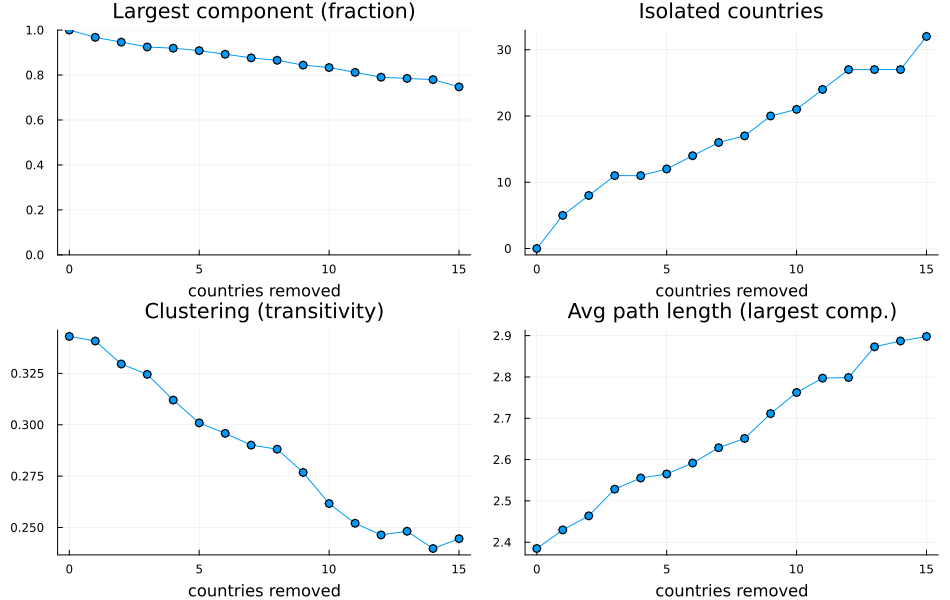

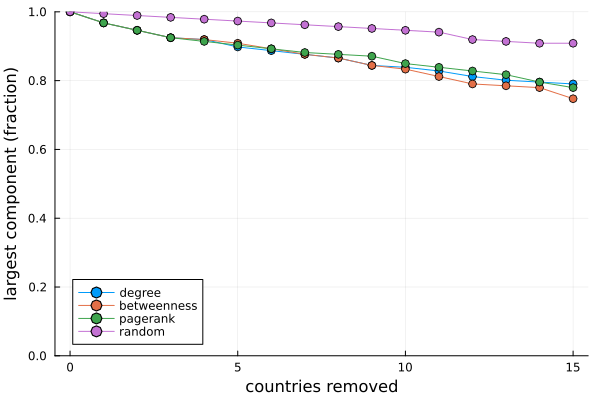

Row,step,degree,betweenness,pagerank,random
,Int64,Float64,Float64,Float64,Float64
1,0,1.0,1.0,1.0,1.0
2,1,0.968,0.968,0.968,0.995
3,2,0.946,0.946,0.946,0.989
4,3,0.925,0.925,0.925,0.984
5,4,0.919,0.919,0.914,0.978
6,5,0.898,0.909,0.903,0.973
7,6,0.887,0.892,0.892,0.968
8,7,0.876,0.876,0.882,0.962
9,8,0.866,0.866,0.876,0.957


In [34]:
# ---------------- Usage ----------------
res = attack_test(net_dv, :betweenness; steps = 15)
summarize_attack(res);

compare_attacks(net_dv, [:degree, :betweenness, :pagerank, :random]; steps = 15)

In [36]:
# ---------------- Example ----------------
# Compare strategies, including a random baseline
for c in (:degree, :betweenness, :pagerank, :random)
    r = attack_test(net_dv, c; steps = 5)
    println(rpad(c, 12), "LCC fraction after 15 removals: ", round(r.history.lcc_frac[end], digits = 3))
end

degree      LCC fraction after 15 removals: 0.898
betweenness LCC fraction after 15 removals: 0.909
pagerank    LCC fraction after 15 removals: 0.903
random      LCC fraction after 15 removals: 0.973


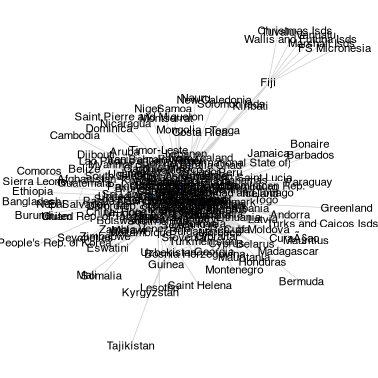

In [40]:
using GraphPlot, Cairo, Compose, Colors

g = net.graph
topo = _topology(g)                 # plain graph, avoids weighted-graph quirks

gplot(topo,
      nodelabel = net.labels,
      nodesize  = degree(topo) .+ 1,       # bigger = more connections
      NODESIZE  = 0.02,
      NODELABELSIZE = 3,
      nodefillc = colorant"steelblue",
      arrowlengthfrac = is_directed(topo) ? 0.02 : 0.0)